In [32]:
!pip install opencv-python matplotlib requests

In [33]:
import requests
import cv2
import numpy as np
import matplotlib.pyplot as plt


Image loaded successfully!
Image shape: (640, 427, 3)


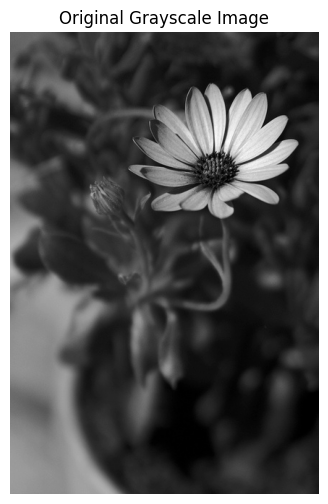

In [34]:
image_url = "https://raw.githubusercontent.com/jwagner/smartcrop-gm/master/test/flower.jpg"

response = requests.get(image_url)

print("Status code:", response.status_code)

image_array = np.frombuffer(response.content, np.uint8)
image = cv2.imdecode(image_array, cv2.IMREAD_COLOR)

if image is None:
    print("Image could not be loaded")
else:
    print("Image loaded successfully!")
    print("Image shape:", image.shape)

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    plt.figure(figsize=(8, 6))
    plt.imshow(gray, cmap="gray")
    plt.title("Original Grayscale Image")
    plt.axis("off")
    plt.show()

In [35]:
# Convert BGR to RGB
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Convert BGR to HSV
hsv = cv2.cvtColor(image, cv2.COLOR_BGR2HSV)

# Convert BGR to LAB
lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)

print("RGB shape:", rgb.shape)
print("HSV shape:", hsv.shape)
print("LAB shape:", lab.shape)

RGB shape: (640, 427, 3)
HSV shape: (640, 427, 3)
LAB shape: (640, 427, 3)


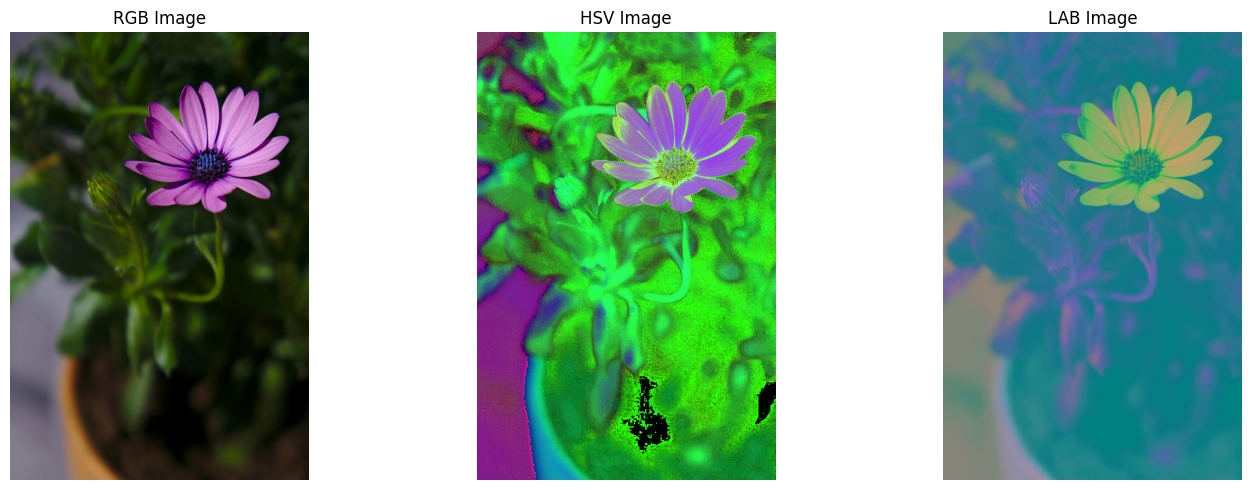

In [36]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(rgb)
plt.title("RGB Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(hsv)
plt.title("HSV Image")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(lab)
plt.title("LAB Image")
plt.axis("off")

plt.tight_layout()
plt.show()

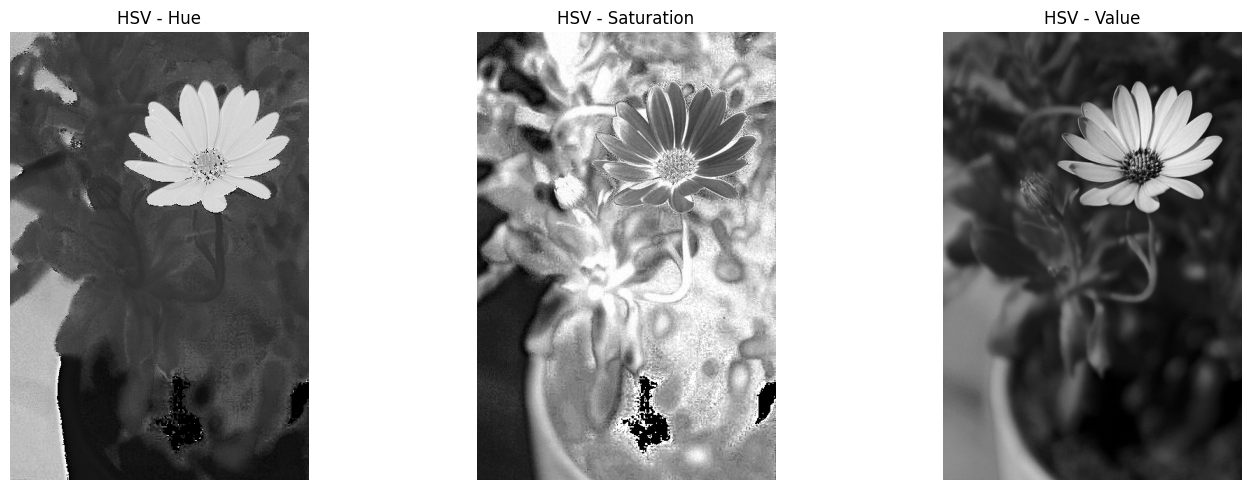

In [37]:
H, S, V = cv2.split(hsv)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(H, cmap="gray")
plt.title("HSV - Hue")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(S, cmap="gray")
plt.title("HSV - Saturation")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(V, cmap="gray")
plt.title("HSV - Value")
plt.axis("off")

plt.tight_layout()
plt.show()

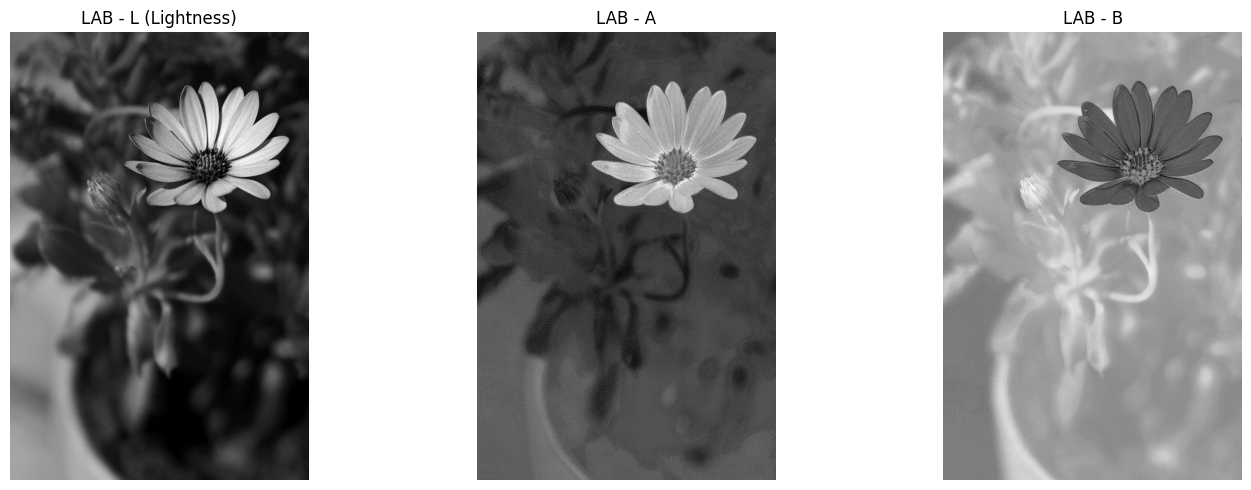

In [38]:
L, A, B = cv2.split(lab)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(L, cmap="gray")
plt.title("LAB - L (Lightness)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(A, cmap="gray")
plt.title("LAB - A")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(B, cmap="gray")
plt.title("LAB - B")
plt.axis("off")

plt.tight_layout()
plt.show()

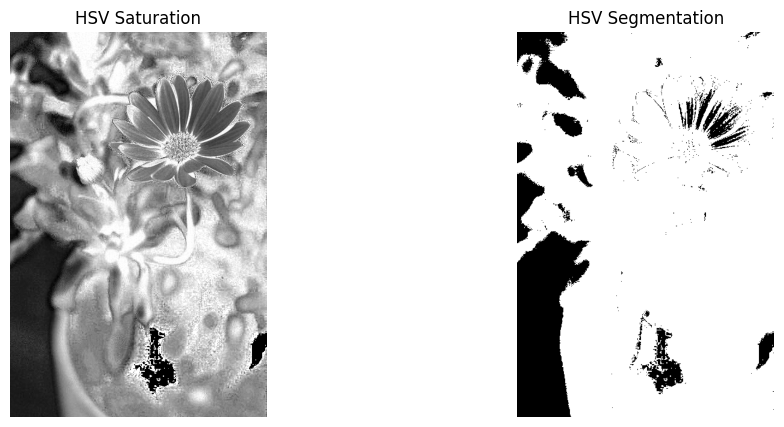

In [39]:
# Threshold the saturation channel

_, hsv_mask = cv2.threshold(
    S,
    80,
    255,
    cv2.THRESH_BINARY
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(S, cmap="gray")
plt.title("HSV Saturation")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(hsv_mask, cmap="gray")
plt.title("HSV Segmentation")
plt.axis("off")

plt.show()

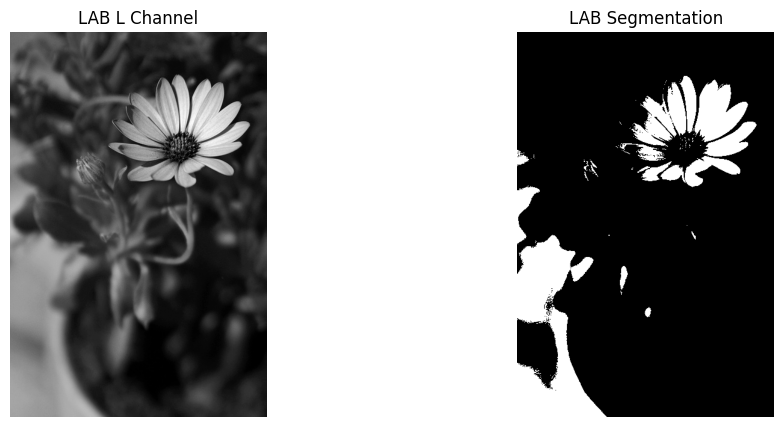

In [40]:
# Threshold the L channel

_, lab_mask = cv2.threshold(
    L,
    120,
    255,
    cv2.THRESH_BINARY
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(L, cmap="gray")
plt.title("LAB L Channel")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(lab_mask, cmap="gray")
plt.title("LAB Segmentation")
plt.axis("off")

plt.show()

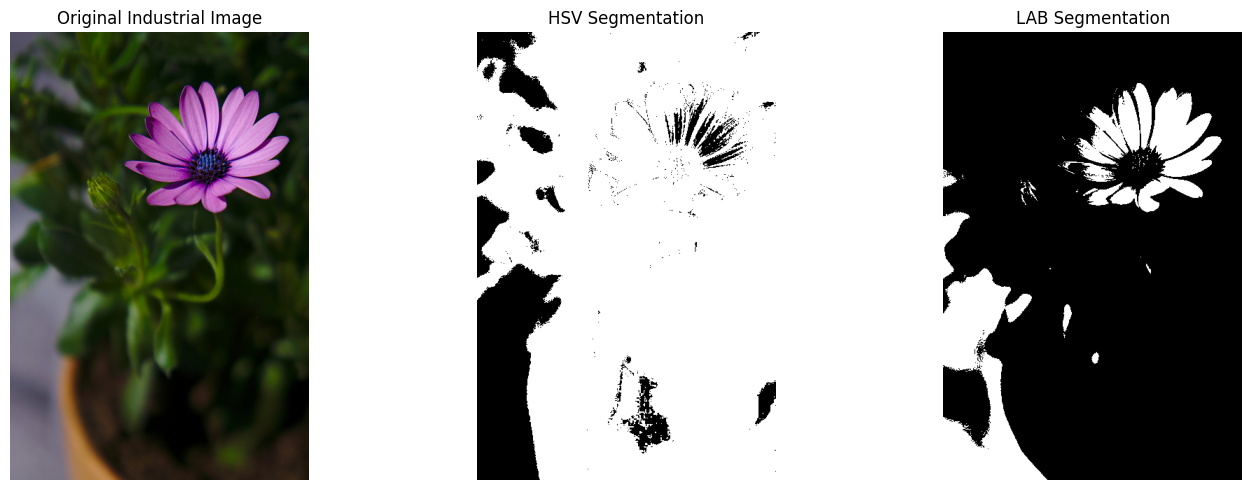

In [41]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(rgb)
plt.title("Original Industrial Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(hsv_mask, cmap="gray")
plt.title("HSV Segmentation")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(lab_mask, cmap="gray")
plt.title("LAB Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()